# デジタル絵馬：ランダム表示方式の再検証

## 目的

文化祭で使用したデジタル絵馬では、投稿済みの絵馬から15件をランダムに選び、
20秒ごとに画面を更新していた。

本Notebookでは、校内公開時に記録された実際の投稿時刻を用いて、
このランダム表示方式を繰り返し再現する。

主に次の値を調べる。

- 投稿から初めて表示されるまでの時間
- 投稿後30秒、1分、2分、3分、5分、10分以内に一度以上表示される割合
- ランダム抽選によって結果がどの程度ばらつくか

## 前提

- 1回の更新で表示する絵馬は15件
- 画面は20秒ごとに更新
- その時点までに投稿された全ての絵馬を抽選対象とする
- 投稿数が15件以下の場合は全て表示する
- 16件以上の場合は15件をランダムに選ぶ
- 実際に20秒更新が何秒から始まっていたかは記録されていない
- そこで、更新開始のタイミングを0秒から19秒までずらした20通りについて確認する
- 各開始タイミングについて1000回ずつシミュレーションする

なお、本分析で扱うのは「画面に表示されたかどうか」である。
実際に利用者が画面を見て、その絵馬を発見したかどうかまでは記録されていないため、
「表示」と「発見」は区別する。

In [1]:
# データ処理に使うライブラリ
import pandas as pd
import numpy as np

# ランダム抽選に使う
import random

# グラフ作成に使う
import matplotlib.pyplot as plt

# Google Colabでファイルをアップロード・ダウンロードするために使う



# -------------------------
# シミュレーションの基本設定
# -------------------------

# 一度に画面へ表示する絵馬の数
DISPLAY_COUNT = 15

# 画面の更新間隔（秒）
INTERVAL_SEC = 20

# 更新開始のタイミング1通りにつき、何回再現するか
NUM_SIMULATIONS = 1000

# 同じシミュレーション結果を再現できるように、乱数の出発点を固定する
SEED = 42


# 初回表示率を調べる時間
# 左側は表に表示する名前、右側は秒数
TIME_THRESHOLDS = {
    "30秒以内": 30,
    "1分以内": 60,
    "2分以内": 120,
    "3分以内": 180,
    "5分以内": 300,
    "10分以内": 600
}

print("設定完了")

設定完了


In [2]:
# -------------------------
# CSVファイルのアップロード (ボタン方式)
# -------------------------
import io
import ipywidgets as widgets
from IPython.display import display

print("1. 下の『Upload』ボタンを押してCSVファイルを選択してください。")
print("2. 選択が完了（数字の『1』等が表示）したら、次のセルを実行してください。\n")

uploader = widgets.FileUpload(
    accept='.csv',  # CSVのみ許可
    multiple=False  # 1ファイルのみ
)
display(uploader)

1. 下の『Upload』ボタンを押してCSVファイルを選択してください。
2. 選択が完了（数字の『1』等が表示）したら、次のセルを実行してください。



FileUpload(value=(), accept='.csv', description='Upload')

In [3]:
# -------------------------
# アップロードされたデータを読み込む
# -------------------------
if not uploader.value:
    print("【エラー】ファイルが選択されていません。上のセルでアップロードしてください。")
else:
    # ipywidgetsのバージョンによってデータの持ち方が違うため両方に対応
    if isinstance(uploader.value, dict):
        # v7以前
        filename = list(uploader.value.keys())[0]
        content = uploader.value[filename]['content']
    else:
        # v8以降
        uploaded_file = uploader.value[0]
        filename = uploaded_file.name
        content = uploaded_file.content
        
    print("読み込んだファイル:", filename)
    
    # メモリ上のバイナリデータをCSVとして読み込む
    try:
        df = pd.read_csv(io.BytesIO(content))
    except UnicodeDecodeError:
        df = pd.read_csv(io.BytesIO(content), encoding="cp932")
        
    display(df.head())
    print("\n列名:", df.columns.tolist())

読み込んだファイル: kounai.csv


,timestamp
0,2026/06/05 13:17:32
1,2026/06/05 13:18:28
2,2026/06/05 13:19:04
3,2026/06/05 13:19:04
4,2026/06/05 13:20:18



列名: ['timestamp']


In [4]:
# -------------------------
# 投稿時刻の整理
# -------------------------

# 今回はCSVの1列目を「投稿時刻」として使用する
timestamp_col = df.columns[0]

# 投稿時刻だけを取り出して、新しい表を作る
posts = df[[timestamp_col]].copy()
posts.columns = ["投稿時刻"]


# 文字列になっている時刻を、Pythonが時刻として扱える形式に変換する
# 変換できない値があった場合はNaT（時刻の欠損値）になる
posts["投稿時刻"] = pd.to_datetime(
    posts["投稿時刻"],
    errors="coerce"
)


# 時刻として読み取れなかった行数を確認する
invalid_count = posts["投稿時刻"].isna().sum()

print("時刻として読み取れなかった行:", invalid_count)


# 読み取れなかった行があれば除外する
posts = posts.dropna(subset=["投稿時刻"])


# 投稿時刻が早い順に並べる
posts = posts.sort_values("投稿時刻").reset_index(drop=True)


# 同じ秒に複数投稿されていても区別できるように、
# 各投稿へ0から始まる番号を付ける
posts["post_id"] = range(len(posts))


# -------------------------
# データの確認
# -------------------------

print("投稿数:", len(posts))
print("最初の投稿:", posts["投稿時刻"].min())
print("最後の投稿:", posts["投稿時刻"].max())

display(posts.head())


# 今回使用する校内公開データは200件の想定なので、
# 件数が違う場合だけ注意を表示する
if len(posts) != 200:
    print("注意：想定していた200件と投稿数が異なります。")

時刻として読み取れなかった行: 0
投稿数: 200
最初の投稿: 2026-06-05 13:17:32
最後の投稿: 2026-06-05 16:12:56


,投稿時刻,post_id
0,2026-06-05 13:17:32,0
1,2026-06-05 13:18:28,1
2,2026-06-05 13:19:04,2
3,2026-06-05 13:19:04,3
4,2026-06-05 13:20:18,4


In [5]:
# -------------------------
# ランダム表示を1回再現する関数
# -------------------------

def simulate_random_display(post_times, refresh_start_sec, rng):
    """
    実際の投稿時刻を使って、
    ランダム表示方式を1回再現する。

    post_times:
        投稿時刻を早い順に並べたデータ

    refresh_start_sec:
        20秒更新を何秒から始めるか。
        0なら 00秒, 20秒, 40秒...
        7なら 07秒, 27秒, 47秒...
        のように更新する。

    rng:
        ランダム抽選に使用する乱数。

    戻り値:
        各投稿について、
        ・投稿時刻
        ・初めて表示された時刻
        ・初回表示までの秒数
        を記録した表。
    """

    # 投稿時刻をリストにする
    post_times = list(pd.to_datetime(post_times))

    num_posts = len(post_times)

    # 最初の投稿が含まれる「分」の先頭を基準にする
    # 例：13:17:32 → 13:17:00
    base_time = pd.Timestamp(post_times[0]).floor("min")

    # 指定した秒から更新を始める
    # 例：refresh_start_sec = 7 → 13:17:07
    current_refresh = (
        base_time
        + pd.Timedelta(seconds=refresh_start_sec)
    )

    # 最初の投稿より後から始まってしまう場合は、
    # 20秒前へ戻して、更新周期を最初の投稿より前から作る
    while current_refresh > post_times[0]:
        current_refresh -= pd.Timedelta(seconds=INTERVAL_SEC)


    # 現在までに投稿され、抽選対象になっているpost_idを入れる
    available_posts = []

    # 次に追加する投稿の番号
    next_post = 0

    # 各投稿が初めて表示された時刻を記録する
    # 最初はまだ一度も表示されていないためNone
    first_display_times = [None] * num_posts

    # まだ一度も表示されていない投稿数
    remaining = num_posts


    # 全ての投稿が最低1回表示されるまで更新を続ける
    while remaining > 0:

        # -------------------------
        # この更新時刻までに投稿された絵馬を追加する
        # -------------------------
        while (
            next_post < num_posts
            and post_times[next_post] <= current_refresh
        ):
            available_posts.append(next_post)
            next_post += 1


        # -------------------------
        # 表示する絵馬を決める
        # -------------------------
        if len(available_posts) > 0:

            # 投稿数が15件以下なら全て表示
            if len(available_posts) <= DISPLAY_COUNT:
                selected_posts = available_posts.copy()

            # 16件以上なら15件をランダムに選ぶ
            else:
                selected_posts = rng.sample(
                    available_posts,
                    DISPLAY_COUNT
                )


            # -------------------------
            # 初めて表示された投稿だけ時刻を記録する
            # -------------------------
            for post_id in selected_posts:

                if first_display_times[post_id] is None:
                    first_display_times[post_id] = current_refresh
                    remaining -= 1


        # 次の20秒後の更新へ進む
        current_refresh += pd.Timedelta(seconds=INTERVAL_SEC)


    # -------------------------
    # 各投稿の待ち時間を計算する
    # -------------------------

    result = pd.DataFrame({
        "post_id": range(num_posts),
        "投稿時刻": post_times,
        "初回表示時刻": first_display_times
    })


    result["初回表示待ち時間_秒"] = (
        result["初回表示時刻"]
        - result["投稿時刻"]
    ).dt.total_seconds()


    return result

In [7]:
# -------------------------
# 1回のシミュレーション結果を集計する関数
# -------------------------

def calculate_metrics(result):
    """
    1回のシミュレーション結果から、
    待ち時間や一定時間以内の初回表示率を計算する。
    """

    waits = result["初回表示待ち時間_秒"].to_numpy()


    # 基本的な待ち時間
    metrics = {
        "平均待ち時間_秒": np.mean(waits),
        "中央値_秒": np.median(waits),
        "最大待ち時間_秒": np.max(waits)
    }


    # -------------------------
    # 投稿後○秒以内に一度以上表示された割合
    # -------------------------

    for label, seconds in TIME_THRESHOLDS.items():

        # 待ち時間が指定時間以下だった投稿の割合を求める
        rate = np.mean(waits <= seconds) * 100

        metrics[f"{label}_初回表示率_%"] = rate


    return metrics

In [8]:
# -------------------------
# 動作確認
# -------------------------

# テスト用の乱数
test_rng = random.Random(SEED)


# 更新開始を0秒として、1回だけシミュレーションする
test_result = simulate_random_display(
    posts["投稿時刻"],
    refresh_start_sec=0,
    rng=test_rng
)


# 結果の先頭を確認
display(test_result.head())


# 集計結果を表示
test_metrics = calculate_metrics(test_result)

print("1回だけ実行した結果")
for key, value in test_metrics.items():
    print(f"{key}: {value:.2f}")


# -------------------------
# 明らかな異常がないか確認
# -------------------------

# 待ち時間がマイナスになっていないか
assert (test_result["初回表示待ち時間_秒"] >= 0).all()

# 全投稿に初回表示時刻が記録されているか
assert test_result["初回表示時刻"].notna().all()

# 投稿数が元データと一致しているか
assert len(test_result) == len(posts)

print()
print("基本的な動作確認：問題なし")

,post_id,投稿時刻,初回表示時刻,初回表示待ち時間_秒
0,0,2026-06-05 13:17:32,2026-06-05 13:17:40,8.0
1,1,2026-06-05 13:18:28,2026-06-05 13:18:40,12.0
2,2,2026-06-05 13:19:04,2026-06-05 13:19:20,16.0
3,3,2026-06-05 13:19:04,2026-06-05 13:19:20,16.0
4,4,2026-06-05 13:20:18,2026-06-05 13:20:20,2.0


1回だけ実行した結果
平均待ち時間_秒: 113.66
中央値_秒: 60.00
最大待ち時間_秒: 1297.00
30秒以内_初回表示率_%: 37.00
1分以内_初回表示率_%: 50.00
2分以内_初回表示率_%: 69.00
3分以内_初回表示率_%: 80.00
5分以内_初回表示率_%: 89.50
10分以内_初回表示率_%: 98.50

基本的な動作確認：問題なし


In [9]:
# -------------------------
# 初回表示まで特に時間がかかった投稿を確認
# -------------------------

longest_waits = (
    test_result
    .sort_values(
        "初回表示待ち時間_秒",
        ascending=False
    )
    .head(10)
)

display(longest_waits)

,post_id,投稿時刻,初回表示時刻,初回表示待ち時間_秒
185,185,2026-06-05 16:08:03,2026-06-05 16:29:40,1297.0
182,182,2026-06-05 16:05:28,2026-06-05 16:21:00,932.0
195,195,2026-06-05 16:12:06,2026-06-05 16:25:20,794.0
137,137,2026-06-05 15:11:16,2026-06-05 15:20:20,544.0
190,190,2026-06-05 16:11:00,2026-06-05 16:19:00,480.0
151,151,2026-06-05 15:28:26,2026-06-05 15:36:00,454.0
187,187,2026-06-05 16:09:19,2026-06-05 16:16:40,441.0
138,138,2026-06-05 15:11:24,2026-06-05 15:18:20,416.0
148,148,2026-06-05 15:25:49,2026-06-05 15:32:40,411.0
174,174,2026-06-05 15:54:44,2026-06-05 16:01:20,396.0


In [10]:
# -------------------------
# 本番シミュレーション（メモリ節約版）
# -------------------------

# 各試行の結果を保存するリスト
all_metrics = []

# 全ての待ち時間（数値のみ）を保存するリスト
all_waits_list = []

# 更新開始のタイミングを0秒 ～ 19秒まで全て試す
for refresh_start_sec in range(INTERVAL_SEC):

    for simulation_no in range(NUM_SIMULATIONS):
        run_seed = (SEED + refresh_start_sec * NUM_SIMULATIONS + simulation_no)
        rng = random.Random(run_seed)

        # ランダム表示を1回再現
        result = simulate_random_display(
            posts["投稿時刻"],
            refresh_start_sec,
            rng
        )

        # 1回分の結果を集計
        metrics = calculate_metrics(result)
        metrics["更新開始秒"] = refresh_start_sec
        metrics["試行番号"] = simulation_no + 1
        all_metrics.append(metrics)

        # ★変更箇所: DataFrameではなく、計算に必要な「待ち時間の秒数」だけをリストに追加する
        all_waits_list.extend(result["初回表示待ち時間_秒"].tolist())

    # 1つの開始タイミングが終わるごとに進捗を表示
    print(f"更新開始 {refresh_start_sec:02d} 秒：{NUM_SIMULATIONS}回 完了")

# リストを表に変換する (これは2万行なので軽い)
all_runs = pd.DataFrame(all_metrics)

# 全待ち時間をNumPy配列にする (400万件の数値データのみなので非常に軽い)
waits_array = np.array(all_waits_list)

print("\n全シミュレーション完了")
print("試行数:", len(all_runs))
print("全待ち時間記録数:", len(waits_array))
display(all_runs.head())

更新開始 00 秒：1000回 完了
更新開始 01 秒：1000回 完了
更新開始 02 秒：1000回 完了
更新開始 03 秒：1000回 完了
更新開始 04 秒：1000回 完了
更新開始 05 秒：1000回 完了
更新開始 06 秒：1000回 完了
更新開始 07 秒：1000回 完了
更新開始 08 秒：1000回 完了
更新開始 09 秒：1000回 完了
更新開始 10 秒：1000回 完了
更新開始 11 秒：1000回 完了
更新開始 12 秒：1000回 完了
更新開始 13 秒：1000回 完了
更新開始 14 秒：1000回 完了
更新開始 15 秒：1000回 完了
更新開始 16 秒：1000回 完了
更新開始 17 秒：1000回 完了
更新開始 18 秒：1000回 完了
更新開始 19 秒：1000回 完了

全シミュレーション完了
試行数: 20000
全待ち時間記録数: 4000000


,平均待ち時間_秒,中央値_秒,最大待ち時間_秒,30秒以内_初回表示率_%,1分以内_初回表示率_%,2分以内_初回表示率_%,3分以内_初回表示率_%,5分以内_初回表示率_%,10分以内_初回表示率_%,更新開始秒,試行番号
0,113.655,60.0,1297.0,37.0,50.0,69.0,80.0,89.5,98.5,0,1
1,132.955,71.0,1386.0,31.5,46.0,65.5,77.5,89.0,96.0,0,2
2,137.655,79.0,888.0,30.0,44.5,61.5,72.5,87.0,97.0,0,3
3,133.855,60.0,1411.0,30.0,50.5,67.0,78.0,87.0,97.0,0,4
4,126.755,59.5,888.0,33.5,50.0,68.5,79.5,88.0,97.0,0,5


In [11]:
# -------------------------
# 集計対象となる指標
# -------------------------

metric_columns = [
    "平均待ち時間_秒",
    "中央値_秒",
    "最大待ち時間_秒",
    "30秒以内_初回表示率_%",
    "1分以内_初回表示率_%",
    "2分以内_初回表示率_%",
    "3分以内_初回表示率_%",
    "5分以内_初回表示率_%",
    "10分以内_初回表示率_%"
]


# 更新開始時刻ごとの集計結果を入れる
summary_rows = []


for refresh_start_sec in range(INTERVAL_SEC):

    # その開始時刻に対応する1000回分だけ取り出す
    group = all_runs[
        all_runs["更新開始秒"] == refresh_start_sec
    ]


    row = {
        "更新開始秒": refresh_start_sec
    }


    # 各指標について
    # ・1000回の平均
    # ・1000回の標準偏差
    # を計算する
    for column in metric_columns:

        values = group[column].to_numpy()

        row[f"{column}_平均"] = np.mean(values)

        # ddof=0 として、
        # 今回得られた1000回の結果そのものの
        # ばらつきを計算する
        row[f"{column}_標準偏差"] = np.std(
            values,
            ddof=0
        )


    summary_rows.append(row)


# 表に変換
summary_by_start = pd.DataFrame(summary_rows)


display(summary_by_start)

,更新開始秒,平均待ち時間_秒_平均,平均待ち時間_秒_標準偏差,中央値_秒_平均,中央値_秒_標準偏差,最大待ち時間_秒_平均,最大待ち時間_秒_標準偏差,30秒以内_初回表示率_%_平均,30秒以内_初回表示率_%_標準偏差,1分以内_初回表示率_%_平均,1分以内_初回表示率_%_標準偏差,2分以内_初回表示率_%_平均,2分以内_初回表示率_%_標準偏差,3分以内_初回表示率_%_平均,3分以内_初回表示率_%_標準偏差,5分以内_初回表示率_%_平均,5分以内_初回表示率_%_標準偏差,10分以内_初回表示率_%_平均,10分以内_初回表示率_%_標準偏差
0,0,128.1390,10.685400,65.0865,7.757014,1115.807,284.733615,32.6005,2.773202,48.5485,3.008055,66.3675,2.942056,77.0410,2.664079,88.2675,2.181214,97.2960,1.078139
1,1,128.1930,10.976431,64.8990,7.853139,1117.272,328.082224,32.9000,2.758985,48.7370,2.981330,66.4585,2.963786,77.0115,2.724173,88.2900,2.206785,97.3385,1.124797
2,2,128.0824,10.673750,64.9585,7.725932,1088.236,291.955576,32.9565,2.640996,48.6950,2.977411,66.3940,2.929465,76.8720,2.689724,88.2385,2.122350,97.3925,1.080599
3,3,128.4187,10.766146,64.9770,7.685569,1113.827,301.392862,32.9995,2.708459,48.5370,2.988165,66.3465,2.950540,76.9070,2.729442,88.1880,2.151431,97.3495,1.127209
4,4,127.1248,10.961181,64.1945,7.655744,1111.573,303.510518,33.5605,2.628325,48.8645,2.922822,66.6285,2.928692,77.0290,2.758108,88.3785,2.132484,97.4005,1.165697
5,5,128.1209,10.636102,65.0845,7.905606,1125.842,320.666096,33.3340,2.606711,48.4390,2.972336,66.2135,2.942646,76.8065,2.657030,88.2005,2.096437,97.3585,1.146616
6,6,127.2435,10.711989,64.1795,7.800162,1119.261,319.948954,33.9420,2.739824,48.8785,3.025638,66.7325,2.893474,77.1015,2.628963,88.3020,2.157961,97.3455,1.111926
7,7,127.0410,10.352270,64.5335,7.647165,1115.962,277.976842,33.6110,2.671737,48.5645,2.971294,66.5375,2.934424,76.9420,2.634793,88.4025,2.127850,97.4060,1.072923
8,8,127.0116,10.290451,64.1090,7.673925,1126.576,317.401440,34.1620,2.556317,48.8155,2.934742,66.5125,2.821452,77.0050,2.580596,88.3100,2.065890,97.3580,1.091254
9,9,127.4394,10.366449,64.3640,7.738088,1119.689,299.019117,34.1460,2.731791,48.6140,3.016041,66.5030,2.783342,77.0105,2.646156,88.3450,2.119074,97.3420,1.095462


In [12]:
# -------------------------
# 更新開始のタイミングによって
# 平均結果がどの程度変わるか確認する
# -------------------------

timing_difference = []


for column in metric_columns:

    mean_column = f"{column}_平均"

    minimum = summary_by_start[mean_column].min()
    maximum = summary_by_start[mean_column].max()

    timing_difference.append({
        "指標": column,
        "20通りの平均値の最小": minimum,
        "20通りの平均値の最大": maximum,
        "最大と最小の差": maximum - minimum
    })


timing_difference = pd.DataFrame(timing_difference)

display(timing_difference)

,指標,20通りの平均値の最小,20通りの平均値の最大,最大と最小の差
0,平均待ち時間_秒,126.9274,128.4187,1.4913
1,中央値_秒,64.1090,65.0865,0.9775
2,最大待ち時間_秒,1088.2360,1126.5760,38.3400
3,30秒以内_初回表示率_%,32.6005,34.1905,1.5900
4,1分以内_初回表示率_%,48.4320,48.8785,0.4465
5,2分以内_初回表示率_%,66.2135,66.7325,0.5190
6,3分以内_初回表示率_%,76.7560,77.1015,0.3455
7,5分以内_初回表示率_%,88.1670,88.4230,0.2560
8,10分以内_初回表示率_%,97.2960,97.4130,0.1170


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 19968 (\N{CJK UNIFIED IDEOGRAPH-4E00}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 20197 (\N{CJK UNIFIED IDEOGRAPH-4EE5}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 34920 (\N{CJK UNIFIED IDEOGRAPH-8868}) missing from font(s) DejaVu Sans.
  fig.canvas

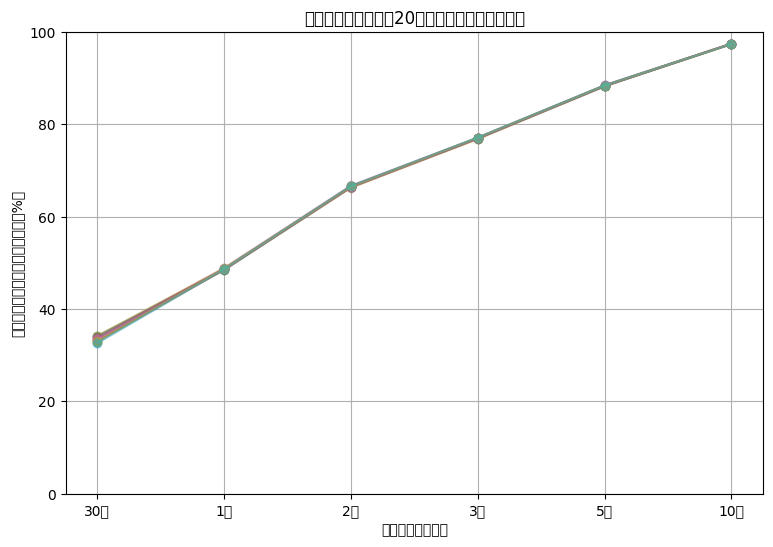

In [13]:
# -------------------------
# 投稿後の経過時間と初回表示率
# -------------------------

# 横軸に使う時間
time_labels = [
    "30秒",
    "1分",
    "2分",
    "3分",
    "5分",
    "10分"
]


# 表から取り出す列名
rate_columns = [
    "30秒以内_初回表示率_%_平均",
    "1分以内_初回表示率_%_平均",
    "2分以内_初回表示率_%_平均",
    "3分以内_初回表示率_%_平均",
    "5分以内_初回表示率_%_平均",
    "10分以内_初回表示率_%_平均"
]


plt.figure(figsize=(9, 6))


# 更新開始0～19秒の20通りを全て描く
for refresh_start_sec in range(INTERVAL_SEC):

    row = summary_by_start[
        summary_by_start["更新開始秒"]
        == refresh_start_sec
    ].iloc[0]

    rates = [
        row[column]
        for column in rate_columns
    ]

    plt.plot(
        time_labels,
        rates,
        marker="o",
        alpha=0.35
    )


plt.xlabel("投稿後の経過時間")
plt.ylabel("一度以上表示された投稿の割合（%）")
plt.title("更新開始タイミング20通りにおける初回表示率")
plt.ylim(0, 100)
plt.grid(True)

plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35430 (\N{CJK UNIFIED IDEOGRAPH-8A66}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 34892 (\N{CJK UNIFIED IDEOGRAPH-884C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 20869 (\N{CJK UNIFIED IDEOGRAPH-5185}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12400 (\N{HIRAGANA LETTER BA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_f

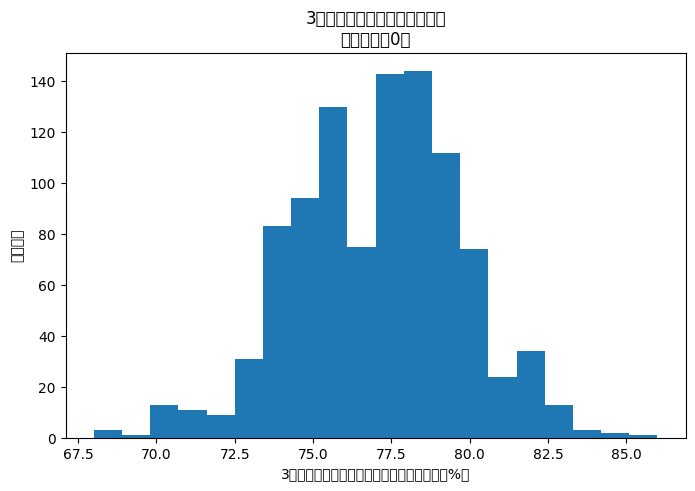

平均: 77.04%
標準偏差: 2.66%


In [14]:
# -------------------------
# 1000回のシミュレーション結果のばらつきを確認
# -------------------------

example_start_sec = 0


example_data = all_runs[
    all_runs["更新開始秒"] == example_start_sec
]


plt.figure(figsize=(8, 5))

plt.hist(
    example_data["3分以内_初回表示率_%"],
    bins=20
)

plt.xlabel("3分以内に一度以上表示された投稿の割合（%）")
plt.ylabel("試行回数")
plt.title(
    f"3分以内初回表示率のばらつき\n"
    f"更新開始：{example_start_sec}秒"
)

plt.show()


# 数値でも確認する
mean_value = example_data[
    "3分以内_初回表示率_%"
].mean()

std_value = example_data[
    "3分以内_初回表示率_%"
].std(ddof=0)


print(f"平均: {mean_value:.2f}%")
print(f"標準偏差: {std_value:.2f}%")

In [15]:
# -------------------------
# 全条件を統合した集計 (メモリ節約版対応)
# -------------------------
overall_metrics = {
    "平均待ち時間_秒": np.mean(waits_array),
    "中央値_秒": np.median(waits_array),
    "最小待ち時間_秒": np.min(waits_array),
    "最大待ち時間_秒": np.max(waits_array)
}

# 初回表示率の計算
for label, seconds in TIME_THRESHOLDS.items():
    rate = np.mean(waits_array <= seconds) * 100
    overall_metrics[f"{label}_初回表示率_%"] = rate

overall_summary = pd.DataFrame([overall_metrics])

print("20条件を等しい重みで扱った統合集計結果:")
display(overall_summary)

20条件を等しい重みで扱った統合集計結果:


,平均待ち時間_秒,中央値_秒,最小待ち時間_秒,最大待ち時間_秒,30秒以内_初回表示率_%,1分以内_初回表示率_%,2分以内_初回表示率_%,3分以内_初回表示率_%,5分以内_初回表示率_%,10分以内_初回表示率_%
0,127.558215,64.0,0.0,3898.0,33.459325,48.630025,66.469575,76.979575,88.309775,97.369575


In [16]:
# -------------------------
# 結果をCSVとして保存
# -------------------------

# 20,000回全ての結果
all_runs.to_csv(
    "random_all_runs.csv",
    index=False,
    encoding="utf-8-sig"
)


# 更新開始タイミングごとの平均・標準偏差
summary_by_start.to_csv(
    "random_summary_by_start_time.csv",
    index=False,
    encoding="utf-8-sig"
)


# 更新開始タイミングによる差
timing_difference.to_csv(
    "random_start_time_difference.csv",
    index=False,
    encoding="utf-8-sig"
)


# 投稿ごとの待ち時間（全400万行）
#all_waits.to_csv(
    #"random_all_waits.csv",
    #index=False,
    #encoding="utf-8-sig"
#)

# 20条件を統合した集計
overall_summary.to_csv(
    "random_overall_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("CSVを保存しました")

CSVを保存しました
